In [4]:
from pathlib import Path
import numpy as np

files = list(Path("/kaggle/input").rglob("metadata.npz"))
assert len(files) == 1, f"找到 {len(files)} 个元数据文件，请检查输入"

prepared_dir = files[0].parent

X = np.load(prepared_dir / "X.npy", mmap_mode="r")
y = np.load(prepared_dir / "y.npy")
info = np.load(prepared_dir / "metadata.npz")

print("数据目录：", prepared_dir)
print("波形：", X.shape)
print("标签：", y.shape)
print("类别：", info["classes"])
print("训练记录：", info["train_mask"].sum())
print("验证记录：", info["val_mask"].sum())
print("测试记录：", info["test_mask"].sum())

数据目录： /kaggle/input/notebooks/zero0388/ecg-insight-01/ecg_prepared
波形： (21388, 12, 1000)
标签： (21388, 5)
类别： ['NORM' 'MI' 'STTC' 'CD' 'HYP']
训练记录： 17084
验证记录： 2146
测试记录： 2158


In [5]:
import random
import numpy as np
import torch

# 固定随机种子，方便对比实验
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch 版本：", torch.__version__)
print("训练设备：", device)

if device.type == "cuda":
    print("GPU：", torch.cuda.get_device_name(0))
else:
    print("当前未检测到 GPU，请检查 Accelerator 设置。")

PyTorch 版本： 2.11.0+cu128
训练设备： cuda
GPU： Tesla T4


In [6]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

class ECGDataset(Dataset):
    def __init__(self, X, y, mask):
        self.X = X
        self.y = y
        self.indices = np.flatnonzero(mask)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        i = self.indices[index]

        # X 是只读映射，复制单条样本后再转为张量
        waveform = torch.from_numpy(
            np.array(self.X[i], dtype=np.float32, copy=True)
        )
        label = torch.from_numpy(
            np.array(self.y[i], dtype=np.float32, copy=True)
        )
        return waveform, label

train_dataset = ECGDataset(X, y, info["train_mask"])
val_dataset = ECGDataset(X, y, info["val_mask"])

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    generator=torch.Generator().manual_seed(42),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

class ECGCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(12, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(64, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.2),
            nn.Linear(128, 5),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = ECGCNN().to(device)

# 多标签任务：每一类分别判断是否阳性
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# 检查一个批次，暂时不更新模型
xb, yb = next(iter(val_loader))
model.eval()

with torch.no_grad():
    logits = model(xb.to(device))
    loss = criterion(logits, yb.to(device))

assert logits.shape == yb.shape
assert torch.isfinite(logits).all()
assert torch.isfinite(loss)

print("输入形状：", xb.shape)
print("输出形状：", logits.shape)
print("标签形状：", yb.shape)
print("检查损失：", round(loss.item(), 4))
print("参数数量：", sum(p.numel() for p in model.parameters()))
print("模型与数据加载器检查通过。")

输入形状： torch.Size([128, 12, 1000])
输出形状： torch.Size([128, 5])
标签形状： torch.Size([128, 5])
检查损失： 0.7066
参数数量： 55205
模型与数据加载器检查通过。


In [7]:
import time
import pandas as pd
from pathlib import Path
from sklearn.metrics import roc_auc_score

save_dir = Path("/kaggle/working/cnn_baseline")
save_dir.mkdir(exist_ok=True)

epochs = 10
best_auc = -float("inf")
history = []

for epoch in range(1, epochs + 1):
    start = time.perf_counter()

    # 训练
    model.train()
    train_loss_sum = 0.0

    for xb, yb in train_loader:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)

        if not torch.isfinite(loss):
            raise RuntimeError("训练损失出现无效值")

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * xb.size(0)

    # 验证：不更新参数
    model.eval()
    val_loss_sum = 0.0
    probabilities = []
    targets = []

    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)

            logits = model(xb)
            loss = criterion(logits, yb)

            val_loss_sum += loss.item() * xb.size(0)
            probabilities.append(torch.sigmoid(logits).cpu().numpy())
            targets.append(yb.cpu().numpy())

    val_prob = np.concatenate(probabilities)
    val_true = np.concatenate(targets)

    train_loss = train_loss_sum / len(train_dataset)
    val_loss = val_loss_sum / len(val_dataset)
    val_auc = roc_auc_score(val_true, val_prob, average="macro")

    # 保存最佳模型与对应验证预测
    if val_auc > best_auc:
        best_auc = val_auc

        torch.save({
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "epoch": epoch,
            "val_macro_auc": float(val_auc),
            "classes": info["classes"].tolist(),
            "seed": 42,
        }, save_dir / "best_model.pt")

        np.savez(
            save_dir / "best_validation_predictions.npz",
            probabilities=val_prob,
            targets=val_true,
            ecg_ids=info["ecg_ids"][info["val_mask"]],
        )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_macro_auc": val_auc,
        "seconds": time.perf_counter() - start,
    })

    pd.DataFrame(history).to_csv(
        save_dir / "training_history.csv", index=False
    )

    print(
        f"第 {epoch:02d}/{epochs} 轮 | "
        f"训练损失 {train_loss:.4f} | "
        f"验证损失 {val_loss:.4f} | "
        f"验证 AUROC {val_auc:.4f} | "
        f"耗时 {history[-1]['seconds']:.1f} 秒",
        flush=True,
    )

print(f"\n训练结束，最佳验证 Macro AUROC：{best_auc:.4f}")
print("模型保存位置：", save_dir / "best_model.pt")

第 01/10 轮 | 训练损失 0.4218 | 验证损失 0.3929 | 验证 AUROC 0.8746 | 耗时 25.1 秒
第 02/10 轮 | 训练损失 0.3308 | 验证损失 0.3275 | 验证 AUROC 0.8949 | 耗时 1.9 秒
第 03/10 轮 | 训练损失 0.3082 | 验证损失 0.3162 | 验证 AUROC 0.9005 | 耗时 1.9 秒
第 04/10 轮 | 训练损失 0.2976 | 验证损失 0.3082 | 验证 AUROC 0.9073 | 耗时 1.9 秒
第 05/10 轮 | 训练损失 0.2913 | 验证损失 0.3098 | 验证 AUROC 0.9084 | 耗时 1.9 秒
第 06/10 轮 | 训练损失 0.2836 | 验证损失 0.3280 | 验证 AUROC 0.9072 | 耗时 1.9 秒
第 07/10 轮 | 训练损失 0.2809 | 验证损失 0.2968 | 验证 AUROC 0.9160 | 耗时 1.9 秒
第 08/10 轮 | 训练损失 0.2762 | 验证损失 0.3079 | 验证 AUROC 0.9129 | 耗时 1.9 秒
第 09/10 轮 | 训练损失 0.2744 | 验证损失 0.3108 | 验证 AUROC 0.9155 | 耗时 1.9 秒
第 10/10 轮 | 训练损失 0.2707 | 验证损失 0.2891 | 验证 AUROC 0.9174 | 耗时 1.9 秒

训练结束，最佳验证 Macro AUROC：0.9174
模型保存位置： /kaggle/working/cnn_baseline/best_model.pt


1：开始导入绘图库
2：开始读取验证预测
3：开始计算指标


,类别,AUROC,精确率,召回率,F1,阳性记录数
0,NORM,0.9385,0.8147,0.8932,0.8521,955
1,MI,0.9151,0.7925,0.6222,0.6971,540
2,STTC,0.9296,0.7567,0.6951,0.7246,528
3,CD,0.9144,0.8338,0.6687,0.7422,495
4,HYP,0.8895,0.6790,0.4104,0.5116,268


验证 Macro F1（阈值 0.5）：0.7055
4：开始绘图


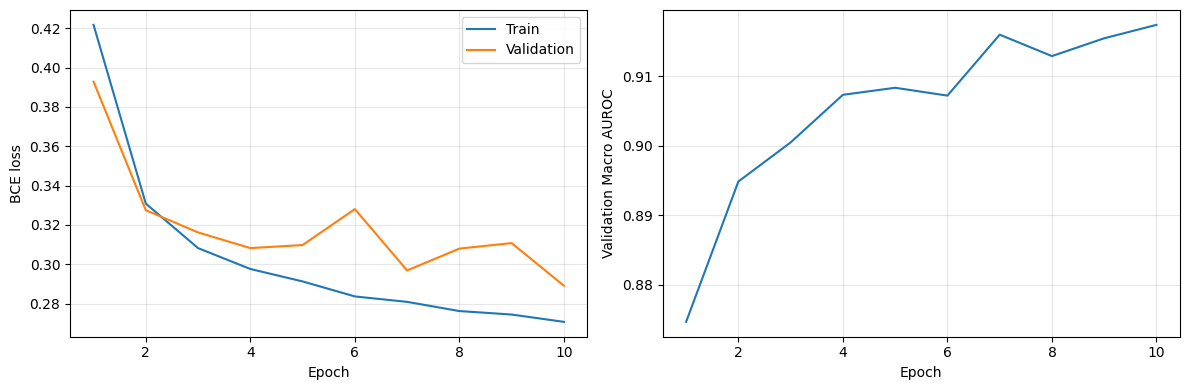

In [9]:
print("1：开始导入绘图库", flush=True)
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_auc_score,
    precision_recall_fscore_support,
)

# 读取最佳轮次的验证预测
print("2：开始读取验证预测", flush=True)
saved = np.load(save_dir / "best_validation_predictions.npz")
val_prob = saved["probabilities"]
val_true = saved["targets"]
val_pred = (val_prob >= 0.5).astype(int)

print("3：开始计算指标", flush=True)
precision, recall, f1, support = precision_recall_fscore_support(
    val_true,
    val_pred,
    average=None,
    zero_division=0,
)

results = pd.DataFrame({
    "类别": info["classes"],
    "AUROC": roc_auc_score(val_true, val_prob, average=None),
    "精确率": precision,
    "召回率": recall,
    "F1": f1,
    "阳性记录数": support,
})

display(results.round(4))
print(f"验证 Macro F1（阈值 0.5）：{f1.mean():.4f}")

results.to_csv(save_dir / "validation_metrics_05.csv", index=False)

# 绘制学习曲线
print("4：开始绘图", flush=True)
curves = pd.read_csv(save_dir / "training_history.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(curves["epoch"], curves["train_loss"], label="Train")
axes[0].plot(curves["epoch"], curves["val_loss"], label="Validation")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCE loss")
axes[0].legend()

axes[1].plot(curves["epoch"], curves["val_macro_auc"])
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation Macro AUROC")

for ax in axes:
    ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(save_dir / "learning_curves.png", dpi=150)
plt.show()

In [10]:
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import precision_recall_fscore_support

thresholds = []
rows = []

for i, cls in enumerate(info["classes"]):
    p, r, t = precision_recall_curve(val_true[:, i], val_prob[:, i])

    # 最后一个精确率/召回率点没有对应阈值，去掉
    scores = 2 * p[:-1] * r[:-1] / (
        p[:-1] + r[:-1] + 1e-12
    )
    best = np.argmax(scores)
    threshold = float(t[best])
    thresholds.append(threshold)

    rows.append({
        "类别": cls,
        "选择的阈值": threshold,
        "原 F1（0.5）": results.iloc[i]["F1"],
        "调阈值后 F1": scores[best],
    })

thresholds = np.array(thresholds)
adjusted_pred = (val_prob >= thresholds).astype(int)

p, r, adjusted_f1, support = precision_recall_fscore_support(
    val_true, adjusted_pred, average=None, zero_division=0
)

comparison = pd.DataFrame(rows)
comparison["调阈值后精确率"] = p
comparison["调阈值后召回率"] = r

display(comparison.round(4))
print(f"调阈值后验证 Macro F1：{adjusted_f1.mean():.4f}")

np.save(save_dir / "thresholds.npy", thresholds)
comparison.to_csv(save_dir / "threshold_comparison.csv", index=False)

,类别,选择的阈值,原 F1（0.5）,调阈值后 F1,调阈值后精确率,调阈值后召回率
0,NORM,0.4090,0.8521,0.8571,0.7950,0.9298
1,MI,0.3113,0.6971,0.7330,0.6832,0.7907
2,STTC,0.3971,0.7246,0.7640,0.7285,0.8030
3,CD,0.3205,0.7422,0.7577,0.7480,0.7677
4,HYP,0.2434,0.5116,0.5874,0.5389,0.6455


调阈值后验证 Macro F1：0.7399


In [11]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import precision_recall_fscore_support

# 加载验证 AUROC 最佳轮次的模型
checkpoint = torch.load(
    save_dir / "best_model.pt",
    map_location=device,
    weights_only=True,
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

thresholds = np.load(save_dir / "thresholds.npy")

test_dataset = ECGDataset(X, y, info["test_mask"])
test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

probabilities = []
targets = []

with torch.no_grad():
    for xb, yb in test_loader:
        logits = model(xb.to(device, non_blocking=True))
        probabilities.append(torch.sigmoid(logits).cpu().numpy())
        targets.append(yb.numpy())

test_prob = np.concatenate(probabilities)
test_true = np.concatenate(targets)
test_pred = (test_prob >= thresholds).astype(int)

p, r, f1, support = precision_recall_fscore_support(
    test_true, test_pred, average=None, zero_division=0
)

test_results = pd.DataFrame({
    "类别": info["classes"],
    "固定阈值": thresholds,
    "AUROC": roc_auc_score(test_true, test_prob, average=None),
    "精确率": p,
    "召回率": r,
    "F1": f1,
    "阳性记录数": support,
})

display(test_results.round(4))

test_auc = roc_auc_score(test_true, test_prob, average="macro")
print(f"测试 Macro AUROC：{test_auc:.4f}")
print(f"测试 Macro F1（验证集阈值）：{f1.mean():.4f}")

# 同时保留统一阈值 0.5 的结果，方便公平比较
_, _, f1_05, _ = precision_recall_fscore_support(
    test_true,
    (test_prob >= 0.5).astype(int),
    average=None,
    zero_division=0,
)
print(f"测试 Macro F1（阈值 0.5）：{f1_05.mean():.4f}")

test_results.to_csv(save_dir / "test_metrics.csv", index=False)
np.savez(
    save_dir / "test_predictions.npz",
    probabilities=test_prob,
    targets=test_true,
    ecg_ids=info["ecg_ids"][info["test_mask"]],
    thresholds=thresholds,
)

,类别,固定阈值,AUROC,精确率,召回率,F1,阳性记录数
0,NORM,0.4090,0.9338,0.7799,0.9200,0.8442,963
1,MI,0.3113,0.9095,0.6826,0.7545,0.7168,550
2,STTC,0.3971,0.9294,0.7276,0.7946,0.7596,521
3,CD,0.3205,0.8970,0.7303,0.7097,0.7198,496
4,HYP,0.2434,0.8833,0.5364,0.6756,0.5980,262


测试 Macro AUROC：0.9106
测试 Macro F1（验证集阈值）：0.7277
测试 Macro F1（阈值 0.5）：0.6978
